Q1.  Write a unique paragraph (5-6 sentences) about your favorite topic (e.g., sports, technology, food, books, etc.). 1. Convert text to lowercase and remove punctua on using re. 2. Tokenize the text into words and sentences. 3. Split using split() and word_tokenize() and compare how Python split and NLTK’s word_tokenize() differ. 4. Remove stopwords (using NLTK's stopwords list). 5. Display word frequency distribu on (excluding stopwords).

Original Text:
 Technology is changing the world every day.
I love learning about artificial intelligence and machine learning.
Computers and smartphones make our lives easier.
Technology helps students learn new skills and explore new ideas.
I enjoy coding because it improves my problem-solving skills.
In the future, technology will make life even better.

Cleaned Text:
 technology is changing the world every day
i love learning about artificial intelligence and machine learning
computers and smartphones make our lives easier
technology helps students learn new skills and explore new ideas
i enjoy coding because it improves my problemsolving skills
in the future technology will make life even better

Word Tokens:
 ['technology', 'is', 'changing', 'the', 'world', 'every', 'day', 'i', 'love', 'learning', 'about', 'artificial', 'intelligence', 'and', 'machine', 'learning', 'computers', 'and', 'smartphones', 'make', 'our', 'lives', 'easier', 'technology', 'helps', 'students', 'learn', 'ne

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


<Axes: xlabel='Samples', ylabel='Counts'>

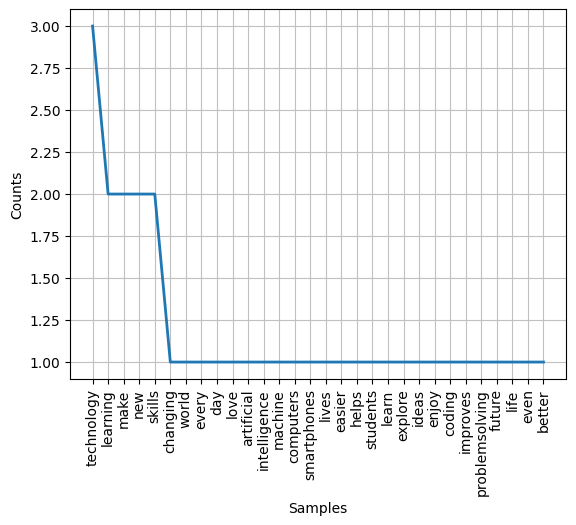

In [3]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """Technology is changing the world every day.
I love learning about artificial intelligence and machine learning.
Computers and smartphones make our lives easier.
Technology helps students learn new skills and explore new ideas.
I enjoy coding because it improves my problem-solving skills.
In the future, technology will make life even better."""

print("Original Text:\n", text)

clean_text = re.sub(r'[^\w\s]', '', text.lower())

print("\nCleaned Text:\n", clean_text)

words = word_tokenize(clean_text)
sentences = sent_tokenize(text)

print("\nWord Tokens:\n", words)
print("\nSentence Tokens:\n", sentences)

split_words = clean_text.split()

print("\nUsing split():\n", split_words)
print("\nUsing word_tokenize():\n", words)

stop_words = set(stopwords.words('english'))

filtered_words = [word for word in words if word not in stop_words]

print("\nWords after removing stopwords:\n", filtered_words)

freq_dist = FreqDist(filtered_words)

print("\nWord Frequency Distribution:")
for word, frequency in freq_dist.items():
    print(word, ":", frequency)

freq_dist.plot()

Q2. Using the same paragraph from Q1: 1. Extract all words with only alphabets using re.findall() 2. Remove stop words using NLTK’s stopword list 3. Perform stemming with PorterStemmer 4. Perform lemma za on with WordNetLemma zer 5. Compare the stemmed and lemma zed outputs and explain when you’d prefer one over the other.

In [2]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

text = """Technology is changing the world every day.
I love learning about artificial intelligence and machine learning.
Computers and smartphones make our lives easier.
Technology helps students learn new skills and explore new ideas.
I enjoy coding because it improves my problem-solving skills.
In the future, technology will make life even better."""

words = re.findall(r'\b[a-zA-Z]+\b', text.lower())

print("Alphabetic Words:\n", words)

stop_words = set(stopwords.words('english'))

filtered_words = [word for word in words if word not in stop_words]

print("\nWords after Stopword Removal:\n", filtered_words)

ps = PorterStemmer()

stemmed_words = [ps.stem(word) for word in filtered_words]

print("\nStemmed Words:\n", stemmed_words)

lemmatizer = WordNetLemmatizer()

lemmatized_words = [
    lemmatizer.lemmatize(word) for word in filtered_words
]

print("\nLemmatized Words:\n", lemmatized_words)

print("\nComparison:")

for original, stem, lemma in zip(
    filtered_words, stemmed_words, lemmatized_words
):
    print(original, " -> Stem:", stem, "| Lemma:", lemma)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Alphabetic Words:
 ['technology', 'is', 'changing', 'the', 'world', 'every', 'day', 'i', 'love', 'learning', 'about', 'artificial', 'intelligence', 'and', 'machine', 'learning', 'computers', 'and', 'smartphones', 'make', 'our', 'lives', 'easier', 'technology', 'helps', 'students', 'learn', 'new', 'skills', 'and', 'explore', 'new', 'ideas', 'i', 'enjoy', 'coding', 'because', 'it', 'improves', 'my', 'problem', 'solving', 'skills', 'in', 'the', 'future', 'technology', 'will', 'make', 'life', 'even', 'better']

Words after Stopword Removal:
 ['technology', 'changing', 'world', 'every', 'day', 'love', 'learning', 'artificial', 'intelligence', 'machine', 'learning', 'computers', 'smartphones', 'make', 'lives', 'easier', 'technology', 'helps', 'students', 'learn', 'new', 'skills', 'explore', 'new', 'ideas', 'enjoy', 'coding', 'improves', 'problem', 'solving', 'skills', 'future', 'technology', 'make', 'life', 'even', 'better']

Stemmed Words:
 ['technolog', 'chang', 'world', 'everi', 'day', 'l

Q3. Choose 3 short texts of your own (e.g., different news headlines, product reviews). 1. Use CountVectorizer to generate the Bag of Words representa on. 2. Use TfidfVectorizer to compute TF-IDF scores. 3. Print and interpret the top 3 keywords from each text using TF-IDF.

In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "This smartphone has an excellent camera and battery life.",
    "The laptop has a fast processor and excellent performance.",
    "This smartphone has a good battery and amazing performance."
]

print("Original Texts:\n")
for i, text in enumerate(texts, 1):
    print("Text", i, ":", text)

count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)

print("\nBag of Words Vocabulary:")
print(count_vectorizer.get_feature_names_out())

print("\nBag of Words Representation:")
print(bow_matrix.toarray())

tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

print("\nTF-IDF Vocabulary:")
print(tfidf_vectorizer.get_feature_names_out())

print("\nTF-IDF Scores:")
print(tfidf_matrix.toarray())

feature_names = tfidf_vectorizer.get_feature_names_out()

print("\nTop 3 Keywords from Each Text:\n")

for i in range(len(texts)):
    scores = tfidf_matrix[i].toarray().flatten()
    top_indices = scores.argsort()[-3:][::-1]

    print("Text", i + 1, ":")
    for index in top_indices:
        print(feature_names[index], ":", round(scores[index], 3))
    print()

Original Texts:

Text 1 : This smartphone has an excellent camera and battery life.
Text 2 : The laptop has a fast processor and excellent performance.
Text 3 : This smartphone has a good battery and amazing performance.

Bag of Words Vocabulary:
['amazing' 'an' 'and' 'battery' 'camera' 'excellent' 'fast' 'good' 'has'
 'laptop' 'life' 'performance' 'processor' 'smartphone' 'the' 'this']

Bag of Words Representation:
[[0 1 1 1 1 1 0 0 1 0 1 0 0 1 0 1]
 [0 0 1 0 0 1 1 0 1 1 0 1 1 0 1 0]
 [1 0 1 1 0 0 0 1 1 0 0 1 0 1 0 1]]

TF-IDF Vocabulary:
['amazing' 'an' 'and' 'battery' 'camera' 'excellent' 'fast' 'good' 'has'
 'laptop' 'life' 'performance' 'processor' 'smartphone' 'the' 'this']

TF-IDF Scores:
[[0.         0.40786601 0.24089223 0.31019261 0.40786601 0.31019261
  0.         0.         0.24089223 0.         0.40786601 0.
  0.         0.31019261 0.         0.31019261]
 [0.         0.         0.24409681 0.         0.         0.31431908
  0.41329182 0.         0.24409681 0.41329182 0.    

Q4. Write 2 short texts (4–6 lines each) describing two different technologies (e.g., AI vs Blockchain). 1. Preprocess and tokenize both texts. 2. Calculate: a. Jaccard Similarity using sets b. Cosine Similarity using TfidfVectorizer + cosine_similarity() c. Analyze which similarity metric gives be er insights in your case.

In [6]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text1 = """Artificial Intelligence enables machines to learn from data.
AI helps computers make decisions and solve problems.
It is used in healthcare, education, and automation.
Machine learning is an important part of artificial intelligence.
AI makes technology smarter and improves efficiency."""

text2 = """Blockchain is a decentralized digital technology.
It stores information in secure and connected blocks.
Blockchain is used in cryptocurrency and financial transactions.
It provides transparency, security, and data protection.
This technology removes the need for central authorities."""

texts = [text1, text2]

stop_words = set(stopwords.words('english'))

processed_texts = []

for text in texts:
    text = re.sub(r'[^a-zA-Z\s]', '', text.lower())
    tokens = word_tokenize(text)
    filtered_tokens = [word for word in tokens if word not in stop_words]
    processed_texts.append(filtered_tokens)

print("Preprocessed Texts:")
print("Text 1:", processed_texts[0])
print("Text 2:", processed_texts[1])

set1 = set(processed_texts[0])
set2 = set(processed_texts[1])

jaccard = len(set1.intersection(set2)) / len(set1.union(set2))

print("\nJaccard Similarity:", round(jaccard, 4))

clean_texts = [' '.join(tokens) for tokens in processed_texts]

tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(clean_texts)

cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])

print("Cosine Similarity:", round(cosine[0][0], 4))

Preprocessed Texts:
Text 1: ['artificial', 'intelligence', 'enables', 'machines', 'learn', 'data', 'ai', 'helps', 'computers', 'make', 'decisions', 'solve', 'problems', 'used', 'healthcare', 'education', 'automation', 'machine', 'learning', 'important', 'part', 'artificial', 'intelligence', 'ai', 'makes', 'technology', 'smarter', 'improves', 'efficiency']
Text 2: ['blockchain', 'decentralized', 'digital', 'technology', 'stores', 'information', 'secure', 'connected', 'blocks', 'blockchain', 'used', 'cryptocurrency', 'financial', 'transactions', 'provides', 'transparency', 'security', 'data', 'protection', 'technology', 'removes', 'need', 'central', 'authorities']

Jaccard Similarity: 0.0667
Cosine Similarity: 0.0699


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Q5. Write a short review for a product or service. 1. Use TextBlob or VADER to find polarity & subjec vity for each review. 2. Classify reviews into Posi ve / Nega ve / Neutral. 3. Create a word cloud using the wordcloud library for all posi ve reviews.

Review 1 : This smartphone has an excellent camera and amazing battery life. I love its performance.
Polarity: 0.7
Subjectivity: 0.83
Sentiment: Positive

Review 2 : The laptop is very slow and its battery drains quickly. I am disappointed with this product.
Polarity: -0.57
Subjectivity: 0.64
Sentiment: Negative

Review 3 : The headphones are okay. The sound quality is average and the design is simple.
Polarity: 0.19
Subjectivity: 0.41
Sentiment: Positive



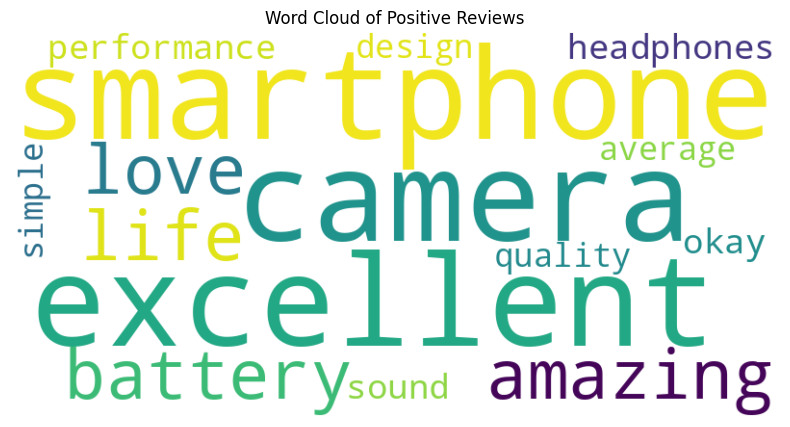

In [7]:
import nltk
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "This smartphone has an excellent camera and amazing battery life. I love its performance.",
    "The laptop is very slow and its battery drains quickly. I am disappointed with this product.",
    "The headphones are okay. The sound quality is average and the design is simple."
]

positive_reviews = []

for i, review in enumerate(reviews, 1):
    blob = TextBlob(review)

    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("Review", i, ":", review)
    print("Polarity:", round(polarity, 2))
    print("Subjectivity:", round(subjectivity, 2))
    print("Sentiment:", sentiment)
    print()

positive_text = " ".join(positive_reviews)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of Positive Reviews")
plt.show()

Q6. Choose your own paragraph (~100 words) as training data. 1. Tokenize text using Tokenizer() from keras.preprocessing.text 2. Create input sequences and build a simple LSTM or Dense model 3. Train the model and generate 2–3 new lines of text star ng from any seed word you provide

In [8]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """Artificial intelligence is changing the world.
Technology helps people solve difficult problems.
Machines can learn from data and improve their performance.
Machine learning is an important part of artificial intelligence.
Students use technology to learn new skills.
Computers can process information and make useful predictions.
Deep learning helps machines understand complex patterns.
Artificial intelligence is used in healthcare education and business.
Robots can perform tasks automatically and save human effort.
Technology makes our daily life easier and faster.
Learning new technologies creates better career opportunities.
The future of artificial intelligence is full of possibilities."""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

input_sequences = []

for line in text.split('.'):
    token_list = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)

max_sequence_len = max(len(seq) for seq in input_sequences)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

X = input_sequences[:, :-1]
y = input_sequences[:, -1]

y = tf.keras.utils.to_categorical(y, num_classes=total_words)

model = Sequential([
    Embedding(total_words, 10),
    LSTM(100),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.fit(X, y, epochs=200, verbose=1)

def generate_text(seed_text, next_words):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]
        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding='pre'
        )

        predicted = model.predict(token_list, verbose=0)
        predicted_word_index = np.argmax(predicted)

        output_word = ""

        for word, index in tokenizer.word_index.items():
            if index == predicted_word_index:
                output_word = word
                break

        if not output_word:
            break

        seed_text += " " + output_word

    return seed_text

print("\nGenerated Text 1:")
print(generate_text("artificial", 3))

print("\nGenerated Text 2:")
print(generate_text("technology", 3))

print("\nGenerated Text 3:")
print(generate_text("machine", 3))

Epoch 1/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.0122 - loss: 4.2345  
Epoch 2/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0854 - loss: 4.2304
Epoch 3/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0732 - loss: 4.2267
Epoch 4/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.0488 - loss: 4.2227
Epoch 5/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0488 - loss: 4.2174
Epoch 6/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0488 - loss: 4.2109
Epoch 7/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0488 - loss: 4.2004    
Epoch 8/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0488 - loss: 4.1887
Epoch 9/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.0488 - loss: 4.1644
Epoch 10/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0488 - loss: 4.1296    
Epoch 11/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0488 - loss: 4.0833
Epoch 12/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0